# HW8

In [8]:
%env CUDA_VISIBLE_DEVICES=1

env: CUDA_VISIBLE_DEVICES=1


# Import packages

In [9]:
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
import torchvision.transforms as transforms
import torch.nn.functional as F
from torch.autograd import Variable
import torchvision.models as models
from torch.optim import Adam, AdamW
from qqdm import qqdm, format_str
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


# Loading data

In [10]:
train = np.load("data/trainingset.npy", allow_pickle=True)
test = np.load("data/testingset.npy", allow_pickle=True)

print(train.shape)
print(test.shape)

(100000, 64, 64, 3)
(19636, 64, 64, 3)


## Random seed

In [11]:
def same_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

same_seeds(48763)

# Models & loss

In [12]:
class fcn_autoencoder(nn.Module):
    def __init__(self):
        super(fcn_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64 * 64 * 3, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3)
        )

        self.decoder = nn.Sequential(
            nn.Linear(3, 12),
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 64 * 64 * 3),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


class conv_autoencoder(nn.Module):
    def __init__(self):
        super(conv_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
			nn.Conv2d(24, 48, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
			nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),
            nn.ReLU(),
			nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


class multi_encoder_autoencoder(nn.Module):
    def __init__(self, kernel_sizes=(3, 5, 7)):
        super().__init__()
        self.encoders = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(3, 32, k, stride=2, padding=k // 2),
                nn.BatchNorm2d(32),
                nn.ReLU(),
                nn.Conv2d(32, 64, k, stride=2, padding=k // 2),
                nn.BatchNorm2d(64),
                nn.ReLU(),
                nn.Conv2d(64, 128, k, stride=2, padding=k // 2),
                nn.BatchNorm2d(128),
                nn.ReLU(),
                nn.Conv2d(128, 256, k, stride=2, padding=k // 2),
                nn.BatchNorm2d(256),
                nn.ReLU(),
            ) for k in kernel_sizes
        ])
        self.fuse = nn.Sequential(
            nn.Conv2d(256 * len(kernel_sizes), 256, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 16, 1),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 128, 4, stride=2, padding=1),   # 8x8
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),   # 16x16
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),    # 32x32
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),     # 64x64
            nn.Tanh(),
        )

    def forward(self, x):
        z = torch.cat([enc(x) for enc in self.encoders], dim=1)
        return self.decoder(self.fuse(z))


class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.enc_out_1 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.enc_out_2 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
			nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),
            nn.ReLU(),
			nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def encode(self, x):
        h1 = self.encoder(x)
        return self.enc_out_1(h1), self.enc_out_2(h1)

    def reparametrize(self, mu, logvar):
        std = logvar.mul(0.5).exp_()
        if torch.cuda.is_available():
            eps = torch.cuda.FloatTensor(std.size()).normal_()
        else:
            eps = torch.FloatTensor(std.size()).normal_()
        eps = Variable(eps)
        return eps.mul(std).add_(mu)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrize(mu, logvar)
        return self.decode(z), mu, logvar


def loss_vae(recon_x, x, mu, logvar, criterion):
    """
    recon_x: generating images
    x: origin images
    mu: latent mean
    logvar: latent log variance
    """
    mse = criterion(recon_x, x)
    KLD_element = mu.pow(2).add_(logvar.exp()).mul_(-1).add_(1).add_(logvar)
    KLD = torch.sum(KLD_element).mul_(-0.5)
    return mse + KLD

# Dataset module

In [13]:
class CustomTensorDataset(TensorDataset):
    def __init__(self, tensors):
        self.tensors = tensors
        if tensors.shape[-1] == 3:
            self.tensors = tensors.permute(0, 3, 1, 2)

    def __getitem__(self, index):
        x = self.tensors[index].to(torch.float32)
        return 2. * x / 255. - 1.

    def __len__(self):
        return len(self.tensors)

# Training

In [14]:
# Training hyperparameters
model_type = "multi"
num_epochs = 100
batch_size = 256
learning_rate = 1e-3

# Build training dataloader
train_dataset = CustomTensorDataset(torch.from_numpy(train))
train_dataloader = DataLoader(train_dataset, sampler=RandomSampler(train_dataset), batch_size=batch_size)

def build_model(model_type):
    model_classes = {
        "fcn": fcn_autoencoder,
        "cnn": conv_autoencoder,
        "multi": multi_encoder_autoencoder,
        "vae": VAE,
    }
    return model_classes[model_type]().to(device)

model = build_model(model_type)
print(model_type, "params:", sum(p.numel() for p in model.parameters()))

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

multi params: 3982259


## Training loop

In [15]:
def forward_loss(model, img, model_type):
    if model_type == "fcn":
        img = img.view(img.shape[0], -1)
    output = model(img)
    if model_type == "vae":
        return loss_vae(output[0], img, output[1], output[2], criterion)
    return criterion(output, img)


best_loss = np.inf
for epoch in range(num_epochs):
    model.train()
    tot_loss = []
    for img in tqdm(train_dataloader, desc=f"epoch {epoch + 1}/{num_epochs}", leave=False):
        img = img.to(device)
        loss = forward_loss(model, img, model_type)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        tot_loss.append(loss.item())
    scheduler.step()

    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model.state_dict(), f"best_model_{model_type}.pt")
    print(f"epoch {epoch + 1:3d}/{num_epochs}  loss {mean_loss:.5f}  best {best_loss:.5f}")

epoch 1/100:   0%|          | 0/391 [00:00<?, ?it/s]

KeyboardInterrupt: 

# Inference

In [ ]:
eval_batch_size = 200

test_dataset = CustomTensorDataset(torch.from_numpy(test))
test_dataloader = DataLoader(test_dataset, sampler=SequentialSampler(test_dataset), batch_size=eval_batch_size)
eval_loss = nn.MSELoss(reduction='none')

model = build_model(model_type)
model.load_state_dict(torch.load(f'best_model_{model_type}.pt', map_location=device))
model.eval()

anomality = []
with torch.no_grad():
    for img in test_dataloader:
        img = img.to(device)
        if model_type == 'fcn':
            img = img.view(img.shape[0], -1)
        output = model(img)
        if model_type == 'vae':
            output = output[0]
        err = eval_loss(output, img).reshape(img.shape[0], 3, 64, 64)
        loss = err[:, :, 16:48, 16:48].reshape(img.shape[0], -1).mean(-1)
        anomality.append(loss)
anomality = torch.sqrt(torch.cat(anomality)).cpu().numpy()

out_file = 'prediction.csv'
df = pd.DataFrame(anomality, columns=['score'])
df.to_csv(out_file, index_label='ID')
print(df.shape)
df.head()

(19636, 1)


,score
0,0.034361
1,0.048198
2,0.043249
3,0.044035
4,0.058666


In [16]:
same_seeds(48763)
fcn_model = fcn_autoencoder().to(device)
print(fcn_model)

fcn_optimizer = torch.optim.AdamW(fcn_model.parameters(), lr=1e-3, weight_decay=1e-2)
fcn_epochs = 20
for epoch in range(fcn_epochs):
    fcn_model.train()
    tot_loss = []
    for img in tqdm(train_dataloader, desc=f"fcn epoch {epoch + 1}/{fcn_epochs}", leave=False):
        img = img.to(device).view(img.shape[0], -1)
        loss = criterion(fcn_model(img), img)
        fcn_optimizer.zero_grad()
        loss.backward()
        fcn_optimizer.step()
        tot_loss.append(loss.item())
    print(f"fcn epoch {epoch + 1:2d}/{fcn_epochs}  loss {np.mean(tot_loss):.5f}")
torch.save(fcn_model.state_dict(), "fcn_report.pt")

fcn_autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=12288, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=12, bias=True)
    (5): ReLU()
    (6): Linear(in_features=12, out_features=3, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=3, out_features=12, bias=True)
    (1): ReLU()
    (2): Linear(in_features=12, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=12288, bias=True)
    (7): Tanh()
  )
)


fcn epoch 1/20:   0%|          | 0/391 [00:00<?, ?it/s]

fcn epoch  1/20  loss 0.17426


fcn epoch 2/20:   0%|          | 0/391 [00:00<?, ?it/s]

fcn epoch  2/20  loss 0.15060


fcn epoch 3/20:   0%|          | 0/391 [00:00<?, ?it/s]

... (31 outputs left out)

fcn epoch 19/20:   0%|          | 0/391 [00:00<?, ?it/s]

fcn epoch 19/20  loss 0.13918


fcn epoch 20/20:   0%|          | 0/391 [00:00<?, ?it/s]

fcn epoch 20/20  loss 0.13922


latent std: [7.057279 6.663382 6.861186]
original latent: [[-9.463507  -1.0524192 -9.37835  ]]


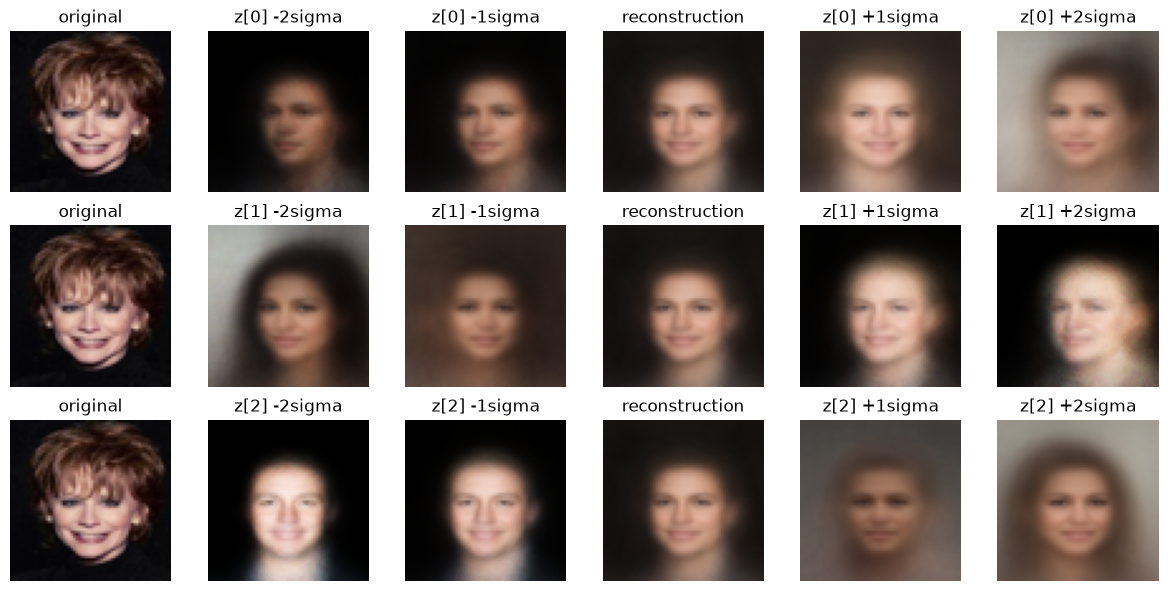

In [ ]:
def to_img(x):
    x = x.view(3, 64, 64).permute(1, 2, 0).cpu().numpy()
    return (x + 1) / 2

fcn_model.eval()
with torch.no_grad():
    sample = torch.stack([train_dataset[i] for i in range(2000)]).to(device).view(2000, -1)
    latent_std = fcn_model.encoder(sample).std(0)
    print('latent std:', latent_std.cpu().numpy())

    img_idx = 1
    x = train_dataset[img_idx].to(device).reshape(1, -1)
    z = fcn_model.encoder(x)
    print('original latent:', z.cpu().numpy())

    deltas = [-2, -1, 0, 1, 2]
    dims = [0, 1, 2]
    fig, axes = plt.subplots(len(dims), len(deltas) + 1, figsize=(2 * (len(deltas) + 1), 2 * len(dims)))
    for r, d in enumerate(dims):
        axes[r, 0].imshow(to_img(x[0]))
        axes[r, 0].set_title("original")
        for c, delta in enumerate(deltas):
            z_new = z.clone()
            z_new[0, d] += delta * latent_std[d]
            recon = fcn_model.decoder(z_new)[0]
            axes[r, c + 1].imshow(to_img(recon).clip(0, 1))
            axes[r, c + 1].set_title(f"z[{d}] {delta:+d}sigma" if delta else "reconstruction")
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("latent.png")
    plt.show()